# Step 1: Data cleaning (Python)
**Project:** Mercedes F1 2021–2025 Driver Performance & Race Strategy Analytics  |  **By:** Aarsh Shrivas

This notebook cleans the raw data **before** any analysis. It reads `Mercedes_F1_2021-2025_Merged.xlsx` and saves `mercedes_clean.csv`, which the EDA notebook (Step 2) then loads.

**What we do:** 1 Load raw data → 2 Inspect → 3 Audit (find errors) → 4 Fix errors → 5 Standardise → 6 Missing values → 7 Add new columns → 8 Validate → 9 Save

## 1. Load the raw data

In [1]:
from pathlib import Path
import re
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.max_columns", 30)

DATA_FILENAME = "Mercedes_F1_2021-2025_Merged.xlsx"
PROJECT_ROOT = None
data_path = None
search_roots = [Path.cwd(), *Path.cwd().parents]
for root in search_roots:
    candidates = [root / "data" / DATA_FILENAME, root / DATA_FILENAME]
    for candidate in candidates:
        if candidate.exists():
            data_path = candidate
            PROJECT_ROOT = root
            break
    if data_path is not None:
        break
if data_path is None:
    raise FileNotFoundError(
        f"Could not find {DATA_FILENAME}. Run this notebook from the project folder, "
        "and keep the workbook in the data/ folder."
    )

OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_FIGURES = OUTPUT_DIR / "figures"
OUTPUT_TABLES = OUTPUT_DIR / "tables"
OUTPUT_FIGURES.mkdir(parents=True, exist_ok=True)
OUTPUT_TABLES.mkdir(parents=True, exist_ok=True)

raw = pd.read_excel(data_path)
df = raw.copy()                       # we clean a copy and keep the raw data untouched
print("Source workbook:", data_path.relative_to(PROJECT_ROOT))
print("Rows and columns:", df.shape)
df[["Season", "GP Name", "Driver", "Quali Pos", "Starting Grid", "Finish Pos", "Points", "Race Date"]].head()


Source workbook: data/Mercedes_F1_2021-2025_Merged.xlsx
Rows and columns: (228, 54)


,Season,GP Name,Driver,Quali Pos,Starting Grid,Finish Pos,Points,Race Date
0,2021,Bahrain,Lewis Hamilton,NaN,2,1.0,25.0,2021-03-28
1,2021,Bahrain,Valtteri Bottas,NaN,3,3.0,16.0,2021-03-28
2,2021,Emilia Romagna,Lewis Hamilton,NaN,1,2.0,19.0,2021-04-18
3,2021,Emilia Romagna,Valtteri Bottas,NaN,8,NaN,0.0,2021-04-18
4,2021,Portugal,Lewis Hamilton,NaN,2,1.0,25.0,2021-05-02


*What to say:* 228 rows = 114 races with 2 Mercedes cars each. One row is one driver in one race.

## 2. Inspect

In [2]:
print(df.dtypes.value_counts())
print()
print("Duplicate rows:", df.duplicated(["Season", "Race No", "Driver"]).sum())
print("Races per season:", (df.groupby("Season").size() / 2).astype(int).to_dict())
print("Team values:", df["Team"].unique())
print("Result status:", df["Result Status"].value_counts().to_dict())

object            27
int64             14
float64           12
datetime64[ns]     1
Name: count, dtype: int64

Duplicate rows: 0
Races per season: {2021: 22, 2022: 22, 2023: 22, 2024: 24, 2025: 24}
Team values: ['Mercedes']
Result status: {'Classified': 208, 'DNF': 18, 'DQ': 2}


In [3]:
# Which columns have missing values, and how many?
missing = df.isna().sum()
missing[missing > 0]

Quali Pos               44
Q1                      44
Q2                      55
Q3                      73
Finish Pos              20
Positions Gained        20
Fastest Lap Time         8
Sprint Grid            180
Sprint Finish Pos      180
Sprint Quali Pos       192
DOTD Place             159
DOTD Vote %            159
Teammate Finish Pos     20
Beat Teammate           40
dtype: int64

## 3. Audit: look for errors

Two kinds of check: **logic checks** (do the numbers agree with each other?) and **format checks** (do dates and times look right?).

In [4]:
# Logic checks: every line should say True or 0
print("Win flag matches finish = 1:", ((df["Finish Pos"] == 1).astype(int) == df["Win"]).all())
print("Total points = race + sprint:", np.isclose(df["Points"] + df["Sprint Points"].fillna(0), df["Total Weekend Points"]).all())
print("Positions gained = grid - finish:", np.isclose((df["Starting Grid"] - df["Finish Pos"]).fillna(-99), df["Positions Gained"].fillna(-99)).all())
print("Laps completed above scheduled laps:", (df["Laps Completed"] > df["Scheduled Laps"]).sum())
print("Two cars sharing a finish position:", df.dropna(subset=["Finish Pos"]).duplicated(["Season", "Race No", "Finish Pos"]).sum())

Win flag matches finish = 1: True
Total points = race + sprint: True
Positions gained = grid - finish: True
Laps completed above scheduled laps: 0
Two cars sharing a finish position: 0


In [5]:
import re  # required for regex checks
# Format checks: dates and times
df["Race Date"] = pd.to_datetime(df["Race Date"])
print("Race years in each season:", df.groupby("Season")["Race Date"].agg(lambda s: sorted(set(s.dt.year))).to_dict())

time_format = r"^\d:\d{2}\.\d{3}$"                  # e.g. 1:31.447
for col in ["Q1", "Q2", "Q3", "Fastest Lap Time", "Lap Record"]:
    for i, v in df[col].dropna().drop_duplicates().items():
        if not re.match(time_format, str(v)):
            print(f"Bad {col}: {v!r}  ({df.loc[i, 'Season']} {df.loc[i, 'GP Name']} {df.loc[i, 'Driver']})")

Race years in each season: {2021: [2021], 2022: [2022], 2023: [2023], 2024: [2024], 2025: [2025, 2029]}
Bad Q2: 'DNF'  (2025 Tag Heuer Grand Prix de Monaco George Russell)
Bad Q2: '1:120.084'  (2025 Qatar Airways Qatar Grand Prix Kimi Antonelli)
Bad Q2: '1:120.186'  (2025 Qatar Airways Qatar Grand Prix George Russell)
Bad Lap Record: '1:16:627'  (2021 Hungary Lewis Hamilton)


*What to say:* the numbers agree with each other, but the format checks found four typing errors: a 2029 race date, two Qatar qualifying times with an extra digit, a "DNF" typed in a time column, and a lap record using `:` instead of `.`.

## 4. Fix the errors
Every fix is written to a log so we can show exactly what changed.

In [6]:
log = []
def note(issue, rows, fix):
    log.append({"issue": issue, "rows_changed": int(rows), "fix": fix if rows else "checked: none found, nothing changed"})

# 1) 2025 Austrian GP date was typed as 2029
mask = df["Race Date"].dt.year == 2029
df.loc[mask, "Race Date"] = pd.Timestamp("2025-06-29")
note("Race date typed as 2029 (2025 Austrian GP)", mask.sum(), "set to 2025-06-29")

# 2) Qatar 2025 Q2 times have an extra digit (1:120.084 should be 1:20.084)
fix_q2 = {"1:120.084": "1:20.084", "1:120.186": "1:20.186"}
mask = df["Q2"].isin(fix_q2)
df["Q2"] = df["Q2"].replace(fix_q2)
note("Q2 time typed with extra digit (Qatar 2025)", mask.sum(), "1:120.084 -> 1:20.084, 1:120.186 -> 1:20.186 (fits between Q1 and Q3)")

# 3) Monaco 2025: the word 'DNF' typed in a time column = no time was set
mask = df["Q2"] == "DNF"
df.loc[mask, "Q2"] = np.nan
note("Word 'DNF' typed in Q2 column (Russell, Monaco 2025)", mask.sum(), "set to missing (no time set)")

# 4) Hungaroring lap record typed with ':' instead of '.'
mask = df["Lap Record"] == "1:16:627"
df.loc[mask, "Lap Record"] = "1:16.627"
note("Lap record typed 1:16:627 (Hungaroring, 2021 rows)", mask.sum(), "changed to 1:16.627")

pd.DataFrame(log)

,issue,rows_changed,fix
0,Race date typed as 2029 (2025 Austrian GP),2,set to 2025-06-29
1,Q2 time typed with extra digit (Qatar 2025),2,"1:120.084 -> 1:20.084, 1:120.186 -> 1:20.186 (fits between Q1 and Q3)"
2,"Word 'DNF' typed in Q2 column (Russell, Monaco 2025)",1,set to missing (no time set)
3,"Lap record typed 1:16:627 (Hungaroring, 2021 rows)",2,changed to 1:16.627


## 5. Standardise

In [7]:
import re  # required for regex checks
# 5a) Remove stray spaces in all text columns
changed = 0
for col in df.columns:
    if pd.api.types.is_string_dtype(df[col]) or df[col].dtype == object:
        s = df[col].astype("string").str.strip()
        changed += (s.fillna("") != df[col].astype("string").fillna("")).sum()
        df[col] = s.where(s.notna(), np.nan).astype(object)
note("Leading or trailing spaces in text columns", changed, "stripped")

# 5b) Same circuit, different names in different seasons -> one name
fix = {
    "Albert Park Circuit": "Albert Park", "Albert Park Grand Prix Circuit": "Albert Park", "Melbourne Grand Prix Circuit": "Albert Park",
    "Aurodromo Jose Carlos Pace": "Interlagos", "Autodromo Jose Carlos Pace": "Interlagos", "Autodromo José Carlos Pace": "Interlagos",
    "Autodromo Enzo e Dino Ferrari": "Imola", "Autodromo Internazionale Enzo e Dino Ferrari": "Imola",
    "Circuit of The Americas": "Circuit of the Americas", "Losail International Circuit": "Lusail International Circuit",
    "Suzuka International Racing Course": "Suzuka Circuit", "Autodromo Nazionale Monza": "Monza",
    "Autodromo Hermanos Rodriguez": "Autódromo Hermanos Rodríguez", "Autodromo Internacional do Algarve": "Portimão",
    "Intercity Istanbul Park": "Istanbul Park",
}
df["Circuit"] = df["Circuit Name"].replace(fix)
note("Circuit names differ between seasons", (df["Circuit"] != df["Circuit Name"]).sum(),
     f"{df['Circuit Name'].nunique()} names -> {df['Circuit'].nunique()} circuits (new column 'Circuit')")

# 5c) '+1 lap' / '+2 laps' written in lower case -> '+1 Lap' / '+2 Laps'
def fix_laps(x):
    m = re.match(r"^\+(\d+) laps?$", str(x))
    return f"+{m.group(1)} Lap" + ("" if m.group(1) == "1" else "s") if m else x
new = df["Time/Retired"].map(fix_laps)
note("'+n laps' written in lower case", (new != df["Time/Retired"]).sum(), "changed to '+1 Lap' / '+2 Laps'")
df["Time/Retired"] = new

# 5d) Dates of birth are text (dd/mm/yyyy) -> real dates
df["Date of Birth"] = pd.to_datetime(df["Date of Birth"], dayfirst=True)

# 5e) Short driver name for charts and tables
df["Drv"] = df["Driver"].str.split().str[-1]

pd.DataFrame(log)

,issue,rows_changed,fix
0,Race date typed as 2029 (2025 Austrian GP),2,set to 2025-06-29
1,Q2 time typed with extra digit (Qatar 2025),2,"1:120.084 -> 1:20.084, 1:120.186 -> 1:20.186 (fits between Q1 and Q3)"
2,"Word 'DNF' typed in Q2 column (Russell, Monaco 2025)",1,set to missing (no time set)
3,"Lap record typed 1:16:627 (Hungaroring, 2021 rows)",2,changed to 1:16.627
4,Leading or trailing spaces in text columns,0,"checked: none found, nothing changed"
5,Circuit names differ between seasons,60,36 names -> 28 circuits (new column 'Circuit')
6,'+n laps' written in lower case,6,changed to '+1 Lap' / '+2 Laps'


*What to say:* 36 circuit names are really 28 circuits. We keep the original name column and add a clean `Circuit` column.

## 6. Missing values
We do **not** fill these in. Each one has a reason, and filling them would invent data.

In [8]:
reasons = {
    "Quali Pos": "2021 has no qualifying data in the source",
    "Q1": "2021 has no qualifying data in the source",
    "Q2": "2021, or car eliminated in Q1, or no time set",
    "Q3": "2021, or car eliminated before Q3",
    "Finish Pos": "DNF or disqualified (no numeric finish)",
    "Positions Gained": "DNF or disqualified",
    "Sprint Finish Pos": "not a sprint weekend",
    "DOTD Place": "only the Driver of the Day top 5 is recorded",
}
table = pd.DataFrame({"missing rows": df[list(reasons)].isna().sum(), "why": pd.Series(reasons)})
table

,missing rows,why
Quali Pos,44,2021 has no qualifying data in the source
Q1,44,2021 has no qualifying data in the source
Q2,56,"2021, or car eliminated in Q1, or no time set"
Q3,73,"2021, or car eliminated before Q3"
Finish Pos,20,DNF or disqualified (no numeric finish)
Positions Gained,20,DNF or disqualified
Sprint Finish Pos,180,not a sprint weekend
DOTD Place,159,only the Driver of the Day top 5 is recorded


## 7. Add new columns for the analysis

In [9]:
def to_seconds(t):                                    # '1:31.447' -> 91.447
    try:
        m, s = str(t).split(":")
        return int(m) * 60 + float(s)
    except Exception:
        return np.nan

for q in ["Q1", "Q2", "Q3"]:
    df[q + " Sec"] = df[q].map(to_seconds)
df["Best Quali Sec"] = df[["Q1 Sec", "Q2 Sec", "Q3 Sec"]].min(axis=1)       # fastest time set at the event

df["Points Total"] = df["Total Weekend Points"]                              # race + sprint points
df["Grid Group"] = pd.cut(df["Starting Grid"], [0, 3, 6, 10, 25], labels=["P1-3", "P4-6", "P7-10", "P11+"])
df["Quali to Race"] = df["Quali Pos"] - df["Finish Pos"]                      # positive = finished ahead of qualifying spot
df["Grid vs Quali"] = df["Quali Pos"] - df["Starting Grid"]                   # negative = penalty or pit-lane start

# Compare each result with that season's average, so strong years don't flatter a circuit
df["Relative Finish"] = df["Finish Pos"] - df.groupby("Season")["Finish Pos"].transform("mean")

df[["Season", "GP Name", "Drv", "Grid Group", "Best Quali Sec", "Relative Finish"]].head()

,Season,GP Name,Drv,Grid Group,Best Quali Sec,Relative Finish
0,2021,Bahrain,Hamilton,P1-3,NaN,-2.794872
1,2021,Bahrain,Bottas,P1-3,NaN,-0.794872
2,2021,Emilia Romagna,Hamilton,P1-3,NaN,-1.794872
3,2021,Emilia Romagna,Bottas,P7-10,NaN,NaN
4,2021,Portugal,Hamilton,P1-3,NaN,-2.794872


*What to say:* *Positions Gained* (grid minus finish) was already in the data and passed the audit. *Relative Finish* below 0 means a better result than the team's usual that season.

## 8. Validate the cleaned data

In [10]:
import re  # required for regex checks
# Re-run the audit on the cleaned data: everything should now pass
print("Race years:", sorted(set(df["Race Date"].dt.year)))
for col in ["Q1", "Q2", "Q3", "Fastest Lap Time", "Lap Record"]:
    bad = [v for v in df[col].dropna().unique() if not re.match(r"^\d:\d{2}\.\d{3}$", str(v))]
    print(f"Bad {col} values:", bad)

assert df.duplicated(["Season", "Race No", "Driver"]).sum() == 0
assert (df.groupby(["Season", "Race No"]).size() == 2).all()
assert df["Circuit"].nunique() == 28
assert df["Race Date"].dt.year.between(2021, 2025).all()
assert df["Q2 Sec"].dropna().between(60, 130).all()          # no impossible lap times

official = {2021: 613.5, 2022: 515, 2023: 409, 2024: 468}    # official constructors' points
points = df.groupby("Season")["Points Total"].sum()
for year, p in official.items():
    assert points[year] == p, (year, points[year])
print("\nAll checks passed. Team points by season:", points.to_dict())

Race years: [2021, 2022, 2023, 2024, 2025]
Bad Q1 values: []
Bad Q2 values: []
Bad Q3 values: []
Bad Fastest Lap Time values: []
Bad Lap Record values: []

All checks passed. Team points by season: {2021: 613.5, 2022: 515.0, 2023: 409.0, 2024: 468.0, 2025: 469.0}


## 9. Save the cleaned data

In [11]:
df.to_csv(OUTPUT_TABLES / "mercedes_clean.csv", index=False)
pd.DataFrame(log).to_csv(OUTPUT_TABLES / "cleaning_log.csv", index=False)
print("Saved cleaned data:", OUTPUT_TABLES / "mercedes_clean.csv", "| shape:", df.shape)
print("Saved cleaning log:", OUTPUT_TABLES / "cleaning_log.csv", "| entries:", len(log))


Saved cleaned data: /mnt/data/Mercedes-F1-Analytics/outputs/tables/mercedes_clean.csv | shape: (228, 65)
Saved cleaning log: /mnt/data/Mercedes-F1-Analytics/outputs/tables/cleaning_log.csv | entries: 7


**Summary of cleaning**
- Found and fixed **4 typing errors** (date, two qualifying times, one text entry in a time column, one lap record).
- Standardised **circuit names** (36 → 28), lap text and dates of birth; removed stray spaces.
- Left missing values as they are and documented why each is missing.
- Added analysis columns: `Circuit`, `Drv`, `Points Total`, `Grid Group`, `Best Quali Sec`, `Quali to Race`, `Grid vs Quali`, `Relative Finish`.
- Validated: no duplicates, 114 races with 2 cars each, and team points match the official totals for 2021–2024.

**Next:** open the EDA notebook (Step 2), which starts from `mercedes_clean.csv`.

---

## Workflow note

The cleaning section saves `outputs/tables/mercedes_clean.csv` and `outputs/tables/cleaning_log.csv`. The EDA section below loads the cleaned data automatically. Keep the source workbook in `data/` and run this notebook from the repository folder (or its `notebooks/` folder).


# Step 2: Exploratory Data Analysis
**Project:** Mercedes F1 2021–2025 Driver Performance & Race Strategy Analytics  |  **By:** Aarsh Shrivas

This notebook starts from the **cleaned** data created in Step 1 at `outputs/tables/mercedes_clean.csv`.

**Steps:** 1 Load → 2 Check → 3 Seasons → 4 Drivers → 5 Qualifying vs race → 6 Circuits → 7 Reliability → 8 Save → 9 Findings


## 1. Load the cleaned data

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings("ignore")

# Theme: Mercedes teal + grey
TEAL, GREY = "#00A19B", "#8d989e"
sns.set_theme(style="whitegrid")

df = pd.read_csv(OUTPUT_TABLES / "mercedes_clean.csv", parse_dates=["Race Date"])
df["Grid Group"] = pd.Categorical(df["Grid Group"], ["P1-3", "P4-6", "P7-10", "P11+"], ordered=True)
print(df.shape)
df[["Season", "GP Name", "Drv", "Quali Pos", "Starting Grid", "Finish Pos", "Points Total", "Circuit"]].head()

(228, 65)


,Season,GP Name,Drv,Quali Pos,Starting Grid,Finish Pos,Points Total,Circuit
0,2021,Bahrain,Hamilton,NaN,2,1.0,25.0,Bahrain International Circuit
1,2021,Bahrain,Bottas,NaN,3,3.0,16.0,Bahrain International Circuit
2,2021,Emilia Romagna,Hamilton,NaN,1,2.0,19.0,Imola
3,2021,Emilia Romagna,Bottas,NaN,8,NaN,0.0,Imola
4,2021,Portugal,Hamilton,NaN,2,1.0,25.0,Portimão


*What to say:* the cleaning step is done, so we go straight to analysis. 228 rows = 114 races with 2 Mercedes cars each.

## 2. Quick check of the cleaned data

In [13]:
print("Duplicate rows:", df.duplicated(["Season", "Race No", "Driver"]).sum())
print("Races per season:", (df.groupby("Season").size() / 2).astype(int).to_dict())
print("Results:", df["Result Status"].value_counts().to_dict())
print("Circuits:", df["Circuit"].nunique())
print("Team points:", df.groupby("Season")["Points Total"].sum().to_dict())

Duplicate rows: 0
Races per season: {2021: 22, 2022: 22, 2023: 22, 2024: 24, 2025: 24}
Results: {'Classified': 208, 'DNF': 18, 'DQ': 2}
Circuits: 28
Team points: {2021: 613.5, 2022: 515.0, 2023: 409.0, 2024: 468.0, 2025: 469.0}


*What to say:* no duplicates, 28 circuits, and team points match the official totals. Missing **Quali Pos** is 2021 only (no 2021 qualifying data in the source) and missing **Finish Pos** is the 18 DNFs and 2 disqualifications.

## 3. Season performance

In [14]:
season = df.groupby("Season").agg(
    races=("Race No", "nunique"),
    points=("Points Total", "sum"),
    wins=("Win", "sum"),
    podiums=("Podium", "sum"),
    avg_quali=("Quali Pos", "mean"),
    avg_finish=("Finish Pos", "mean"),
    dnfs=("DNF", "sum"))
season["points_per_race"] = season["points"] / season["races"]
season.round(2)

,races,points,wins,podiums,avg_quali,avg_finish,dnfs,points_per_race
Season,,,,,,,,
2021,22,613.5,9,28,NaN,3.79,5,27.89
2022,22,515.0,1,17,6.43,4.88,2,23.41
2023,22,409.0,0,8,6.43,5.74,4,18.59
2024,24,468.0,4,9,6.83,5.73,3,19.50
2025,24,469.0,2,12,6.48,6.20,4,19.54


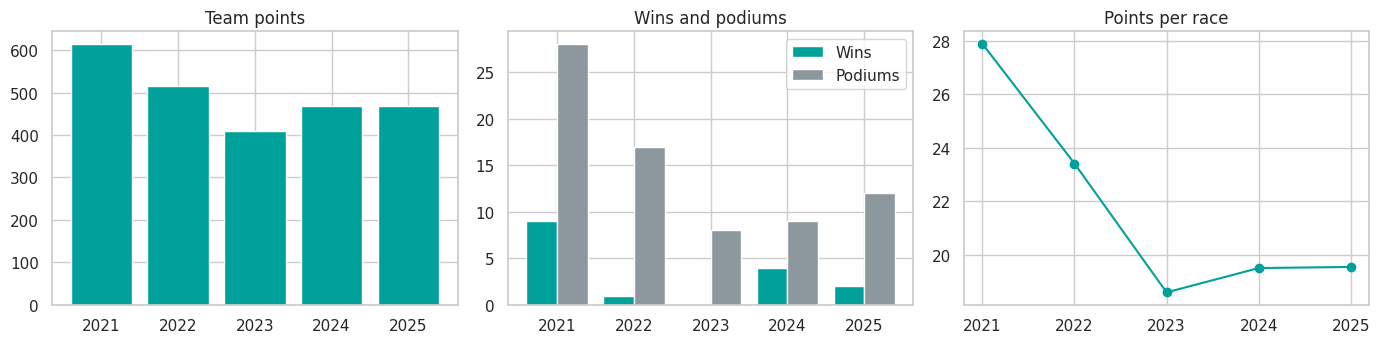

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))

ax[0].bar(season.index, season["points"], color=TEAL)
ax[0].set_title("Team points")

ax[1].bar(season.index - 0.2, season["wins"], width=0.4, color=TEAL, label="Wins")
ax[1].bar(season.index + 0.2, season["podiums"], width=0.4, color=GREY, label="Podiums")
ax[1].set_title("Wins and podiums")
ax[1].legend()

ax[2].plot(season.index, season["points_per_race"], marker="o", color=TEAL)
ax[2].set_title("Points per race")

plt.tight_layout()
plt.savefig(OUTPUT_FIGURES / "season_overview.png", dpi=150)
plt.show()

*What to say:* points fell from 613.5 in 2021 to 409 in 2023, then recovered to 468 in 2024 and 469 in 2025. Wins went 9, 1, 0, 4, 2. Points per race is the fairest comparison because 2024 and 2025 had 24 races against 22 before.

## 4. Drivers

In [16]:
drivers = df.groupby(["Season", "Drv"]).agg(
    starts=("Driver", "size"),
    wins=("Win", "sum"),
    podiums=("Podium", "sum"),
    points=("Points Total", "sum"),
    avg_quali=("Quali Pos", "mean"),
    avg_finish=("Finish Pos", "mean"),
    finish_spread=("Finish Pos", "std"),
    dnfs=("DNF", "sum"))
drivers.round(2)

starts  wins  podiums  points  avg_quali  avg_finish  finish_spread  dnfs
Season Drv                                                                                 
2021   Bottas         22     1       11   226.0        NaN        5.00           3.93     4
       Hamilton       22     8       17   387.5        NaN        2.76           3.19     1
2022   Hamilton       22     0        9   240.0       6.41        5.38           4.15     1
       Russell        22     1        8   275.0       6.45        4.38           2.62     1
2023   Hamilton       22     0        6   234.0       6.36        4.90           2.10     1
       Russell        22     0        2   175.0       6.50        6.63           3.79     3
2024   Hamilton       24     2        5   223.0       8.50        5.86           3.04     2
       Russell        24     2        4   245.0       5.17        5.59           3.22     1
2025   Antonelli      24     0        3   150.0       8.58        8.20           4.98     4
       Russell        24     2        9   319.0       4.38        4.54           2.50     0

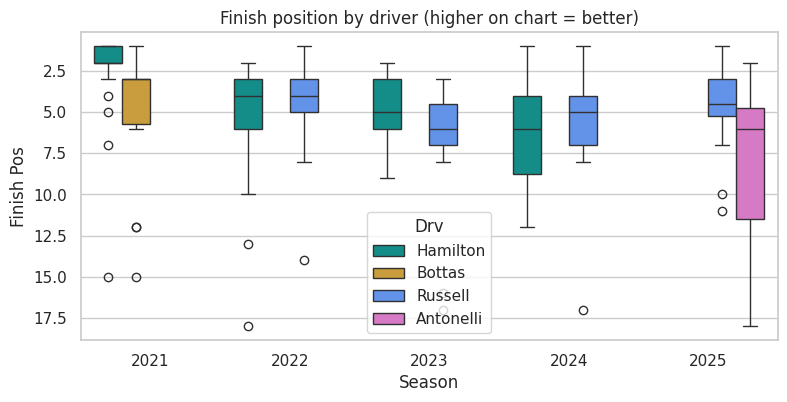

In [17]:
colors = {"Hamilton": TEAL, "Bottas": "#e0a526", "Russell": "#4c8dff", "Antonelli": "#e56bd0"}

plt.figure(figsize=(9, 4))
sns.boxplot(data=df, x="Season", y="Finish Pos", hue="Drv", palette=colors)
plt.gca().invert_yaxis()                       # top of chart = better position
plt.title("Finish position by driver (higher on chart = better)")
plt.savefig(OUTPUT_FIGURES / "driver_finish.png", dpi=150)
plt.show()

*What to say:* a smaller box means a more consistent driver. `finish_spread` is the same idea as a number: lower is steadier.

### Teammate comparison
How often did one driver finish ahead of the other? (only races where both cars finished)

In [18]:
pairs = df.pivot_table(index=["Season", "Race No"], columns="Drv", values="Finish Pos")

def compare(a, b, seasons):
    x = pairs.loc[seasons, [a, b]].dropna()
    a_ahead = (x[a] < x[b]).sum()
    b_ahead = (x[b] < x[a]).sum()
    p = stats.wilcoxon(x[a], x[b]).pvalue          # p < 0.05 means the gap is probably not luck
    print(f"{a} vs {b}: {a} ahead {a_ahead}, {b} ahead {b_ahead}  (p = {p:.4f})")

compare("Hamilton", "Bottas", [2021])
compare("Hamilton", "Russell", [2022, 2023, 2024])
compare("Russell", "Antonelli", [2025])

Hamilton vs Bottas: Hamilton ahead 14, Bottas ahead 3  (p = 0.0290)
Hamilton vs Russell: Hamilton ahead 28, Russell ahead 29  (p = 0.5686)
Russell vs Antonelli: Russell ahead 17, Antonelli ahead 3  (p = 0.0007)


*What to say:* Hamilton clearly beat Bottas in 2021 (p = 0.029). Hamilton and Russell were level in 2022–24 (28 to 29, p = 0.57). Russell clearly beat Antonelli in 2025 (p = 0.0007). A p-value under 0.05 means the difference is unlikely to be chance.

## 5. Does qualifying decide the race?

In [19]:
d = df.dropna(subset=["Starting Grid", "Finish Pos"])      # only cars that finished

rho, p = stats.spearmanr(d["Starting Grid"], d["Finish Pos"])
print(f"Correlation between grid and finish = {rho:.2f} (1 = perfect link)")

groups = d.groupby("Grid Group", observed=True).agg(
    starts=("Driver", "size"),
    avg_finish=("Finish Pos", "mean"),
    podium_rate=("Podium", "mean"),
    win_rate=("Win", "mean"))
groups.round(2)

Correlation between grid and finish = 0.55 (1 = perfect link)


,starts,avg_finish,podium_rate,win_rate
Grid Group,,,,
P1-3,62,3.74,0.68,0.23
P4-6,78,4.81,0.31,0.01
P7-10,36,6.31,0.14,0.03
P11+,32,8.38,0.09,0.00


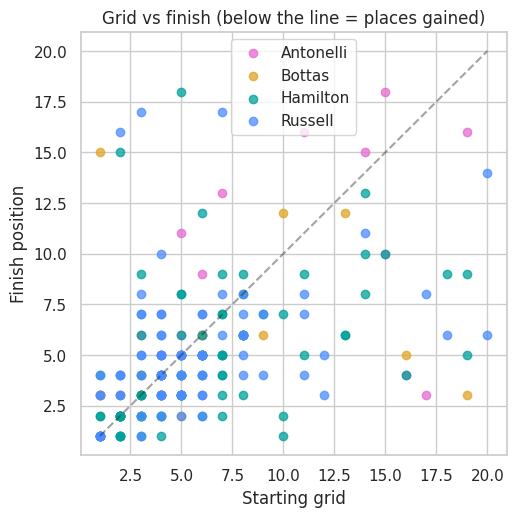

Wins from pole: 8 of 17


In [20]:
plt.figure(figsize=(5.5, 5.5))
for name, g in d.groupby("Drv"):
    plt.scatter(g["Starting Grid"], g["Finish Pos"], color=colors[name], label=name, alpha=0.75)
plt.plot([1, 20], [1, 20], "k--", alpha=0.4)               # dashed line = finished where they started
plt.xlabel("Starting grid")
plt.ylabel("Finish position")
plt.title("Grid vs finish (below the line = places gained)")
plt.legend()
plt.savefig(OUTPUT_FIGURES / "grid_vs_finish.png", dpi=150)
plt.show()

pole = d[d["Starting Grid"] == 1]
print(f"Wins from pole: {int(pole['Win'].sum())} of {len(pole)}")

*What to say:* the link is moderate (0.55). Starting in the top 3 gave a podium 68% of the time, against 9% from P11 or lower. Mercedes won 8 of 17 races from pole (47%). Qualifying matters a lot but does not decide everything.

## 6. Circuits

In [21]:
# "Relative Finish" was added in the cleaning step: each result compared with that season's average

circuits = df.groupby("Circuit").agg(
    starts=("Driver", "size"),
    podiums=("Podium", "sum"),
    avg_finish=("Finish Pos", "mean"),
    relative_finish=("Relative Finish", "mean"),
    dnfs=("DNF", "sum"))

circuits = circuits[circuits["starts"] >= 6]               # skip circuits with very few races
circuits = circuits.sort_values("relative_finish")          # best first
circuits.round(2)

,starts,podiums,avg_finish,relative_finish,dnfs
Circuit,,,,,
Circuit Gilles-Villeneuve,8,5,3.00,-2.62,1
Las Vegas Strip Circuit,6,4,3.83,-2.06,0
Circuit de Barcelona-Catalunya,10,6,3.11,-2.06,1
Silverstone Circuit,10,5,3.71,-1.41,3
Interlagos,10,5,3.89,-1.33,1
Red Bull Ring,12,5,3.91,-1.01,1
Hungaroring,10,5,4.56,-0.88,1
Bahrain International Circuit,10,4,4.80,-0.47,0
Lusail International Circuit,8,1,5.33,-0.23,2


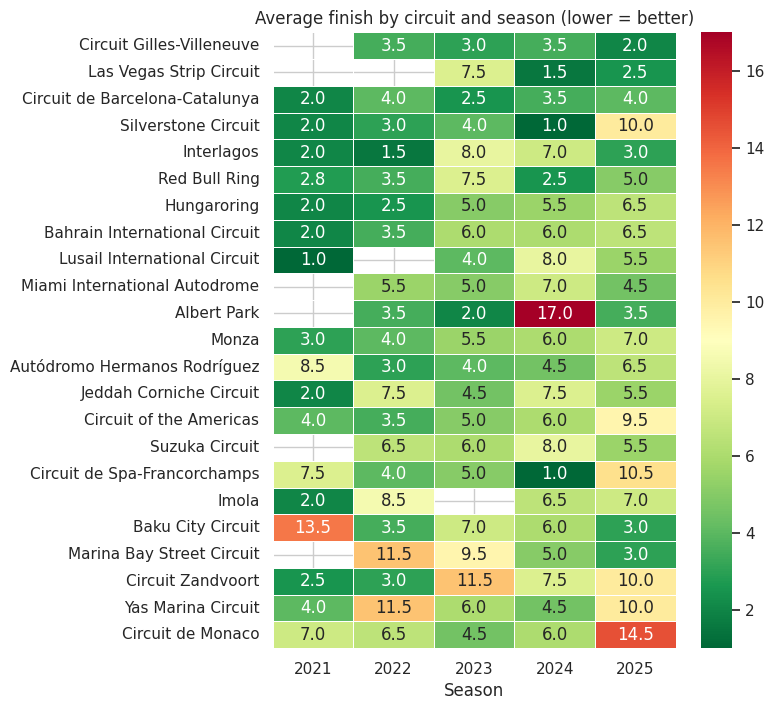

In [22]:
heat = df.pivot_table(index="Circuit", columns="Season", values="Finish Pos", aggfunc="mean")
heat = heat.loc[circuits.index]

plt.figure(figsize=(6.5, 8))
sns.heatmap(heat, annot=True, fmt=".1f", cmap="RdYlGn_r", linewidths=0.4)
plt.title("Average finish by circuit and season (lower = better)")
plt.ylabel("")
plt.savefig(OUTPUT_FIGURES / "circuit_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

*What to say:* *relative_finish* below 0 means better than the team's usual result that season. Best: Canada, Las Vegas, Barcelona. Weakest: Monaco, Abu Dhabi, Zandvoort. Each circuit has only 6–12 starts, so treat small differences carefully.

## 7. Reliability

In [23]:
reliability = df.groupby("Season").agg(starts=("Driver", "size"), dnfs=("DNF", "sum"))
reliability["dnf_rate"] = (reliability["dnfs"] / reliability["starts"]).round(3)
print(reliability)

print()
df[df["Result Status"] != "Classified"][["Season", "GP Name", "Drv", "Result Status", "Laps Completed"]]

        starts  dnfs  dnf_rate
Season                        
2021        44     5     0.114
2022        44     2     0.045
2023        44     4     0.091
2024        48     3     0.062
2025        48     4     0.083



,Season,GP Name,Drv,Result Status,Laps Completed
3,2021,Emilia Romagna,Bottas,DNF,30
9,2021,Monaco,Bottas,DNF,29
21,2021,Hungary,Bottas,DNF,0
27,2021,Italy,Hamilton,DNF,25
39,2021,Qatar,Bottas,DNF,48
63,2022,Lenovo British GP,Russell,DNF,0
71,2022,Rolex Belgian GP,Hamilton,DNF,0
93,2023,Rolex Australian GP,Russell,DNF,17
103,2023,Pirelli Grand Prix du Canada,Russell,DNF,53
121,2023,Qatar Airways Qatar GP,Hamilton,DNF,0


*What to say:* 18 retirements and 2 disqualifications in 228 starts. The source does not say why cars retired, so we can count DNFs but not separate mechanical failures from crashes.

## 8. Save the results

## 9. Findings
1. **Performance dropped after 2021 and then levelled off.** Points: 613.5, 515, 409, 468, 469.
2. **Qualifying matters but does not decide the race.** Correlation 0.55. Podium rate 68% from P1–3 vs 9% from P11+. 8 wins from 17 poles.
3. **Teammates:** Hamilton beat Bottas (2021) and Russell beat Antonelli (2025) clearly; Hamilton and Russell were level in 2022–24.
4. **Circuits:** Canada, Las Vegas and Barcelona were strongest; Monaco, Abu Dhabi and Zandvoort weakest (small samples).
5. **Reliability** was a small factor: 18 DNFs in 228 starts.

**Limits:** no 2021 qualifying data; no pit-stop, tyre or retirement-cause data (needed for the strategy part of the project); results describe what happened, not why.

**Next:** use `mercedes_clean.csv` for the SQL model and the Power BI dashboard.

## 10. Additional points and qualifying analysis

These extra charts compare total season points and driver points, then quantify the association between starting grid and finishing position and summarize qualifying positions.

## 10. Additional points and qualifying analysis

The following charts are separated into individual cells so each can be run and reviewed independently. Points are summed from the source column `Points Total`; use the Race + Sprint label only if the source data includes both race and sprint points.

In [24]:
# Prepare summaries for the additional charts
season_summary = df.groupby('Season').agg(
    Total_Weekend_Points=('Points Total', 'sum')
)

driver_summary = df.groupby(['Season', 'Drv']).agg(
    Total_Weekend_Points=('Points Total', 'sum')
)
season_summary

,Total_Weekend_Points
Season,
2021,613.5
2022,515.0
2023,409.0
2024,468.0
2025,469.0


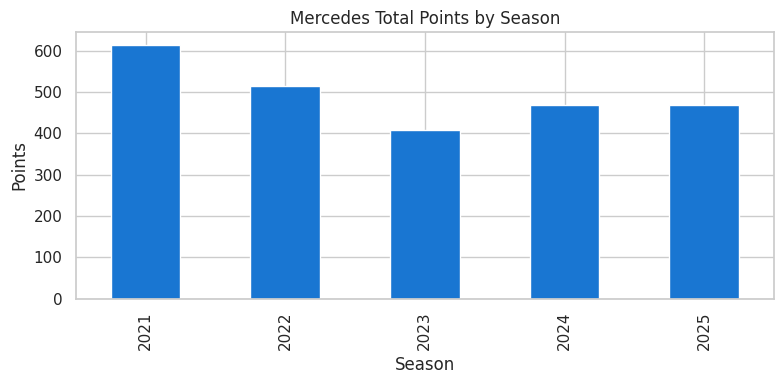

In [25]:
# 1. Mercedes total points by season
plt.figure(figsize=(8, 4))
season_summary['Total_Weekend_Points'].plot(kind='bar', color='#1976D2')
plt.title('Mercedes Total Points by Season')
plt.xlabel('Season')
plt.ylabel('Points')
plt.tight_layout()
plt.show()

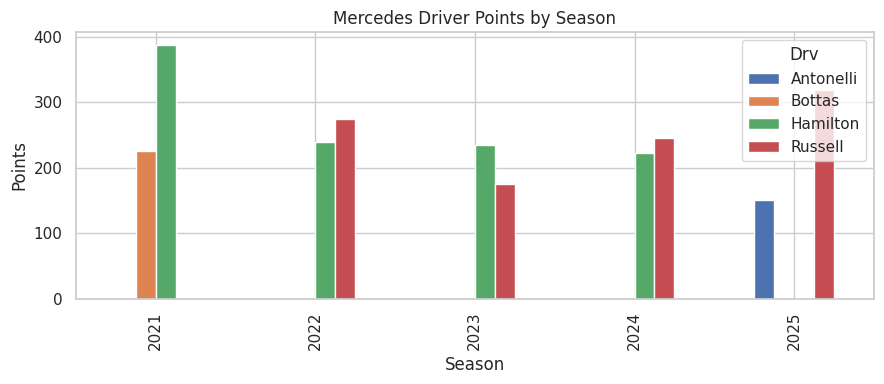

In [26]:
# 2. Mercedes driver points by season
points_by_driver = driver_summary['Total_Weekend_Points'].unstack('Drv')
points_by_driver.plot(kind='bar', figsize=(9, 4))
plt.title('Mercedes Driver Points by Season')
plt.xlabel('Season')
plt.ylabel('Points')
plt.tight_layout()
plt.show()

In [27]:
# 3. Starting grid vs. race finish: Spearman correlation
valid_race_results = df.dropna(subset=['Starting Grid', 'Finish Pos'])
correlation = valid_race_results[['Starting Grid', 'Finish Pos']].corr(method='spearman').iloc[0, 1]
print(f'Spearman correlation between grid and finish position: {correlation:.2f}')
print('A positive value means a worse starting position generally goes with a worse finishing position; this is an association, not proof of cause.')

Spearman correlation between grid and finish position: 0.55
A positive value means a worse starting position generally goes with a worse finishing position; this is an association, not proof of cause.


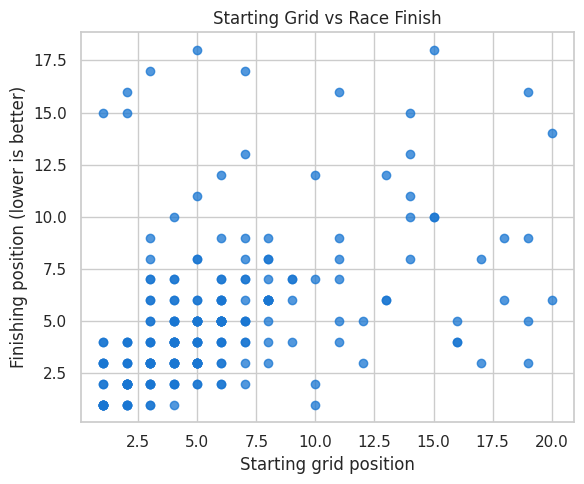

In [28]:
# 4. Scatter plot: starting grid vs. race finish
plt.figure(figsize=(6, 5))
plt.scatter(
    valid_race_results['Starting Grid'],
    valid_race_results['Finish Pos'],
    alpha=0.75,
    color='#1976D2'
)
plt.title('Starting Grid vs Race Finish')
plt.xlabel('Starting grid position')
plt.ylabel('Finishing position (lower is better)')
plt.tight_layout()
plt.show()

Average qualifying position by driver (available data only):


Drv,Antonelli,Hamilton,Russell
Season,,,
2022,NaN,6.41,6.45
2023,NaN,6.36,6.50
2024,NaN,8.50,5.17
2025,8.58,NaN,4.38


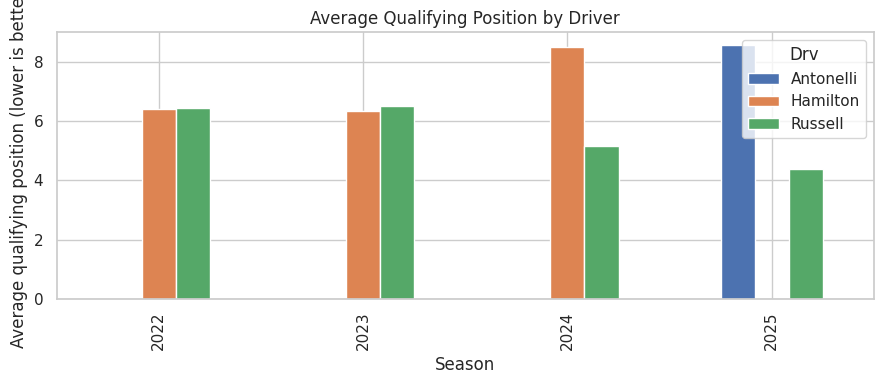

In [29]:
# 5. Average qualifying position by driver and season
# Standard qualifying data is missing for 2021 in this source, so available data may begin in 2022.
valid_qualifying = df.dropna(subset=['Quali Pos'])
qualifying_summary = (
    valid_qualifying.groupby(['Season', 'Drv'])['Quali Pos']
    .mean()
    .unstack('Drv')
    .round(2)
)
print('Average qualifying position by driver (available data only):')
display(qualifying_summary)

qualifying_summary.plot(kind='bar', figsize=(9, 4))
plt.title('Average Qualifying Position by Driver')
plt.xlabel('Season')
plt.ylabel('Average qualifying position (lower is better)')
plt.tight_layout()
plt.show()

## Final step: Save results

Run the final cell below after running the analysis cells to export the summary tables and supporting data as CSV files.

In [30]:
# Save all summary tables and analysis results at the end of the notebook
season.to_csv(OUTPUT_TABLES / 'season_summary.csv')
drivers.to_csv(OUTPUT_TABLES / 'driver_summary.csv')
circuits.to_csv(OUTPUT_TABLES / 'circuit_summary.csv')
season_summary.to_csv(OUTPUT_TABLES / 'additional_season_points_summary.csv')
driver_summary.to_csv(OUTPUT_TABLES / 'additional_driver_points_summary.csv')
qualifying_summary.to_csv(OUTPUT_TABLES / 'qualifying_summary.csv')
valid_race_results.to_csv(OUTPUT_TABLES / 'valid_race_results_for_grid_finish.csv', index=False)
print(f'Saved summary CSV files to {OUTPUT_TABLES}.')

Saved summary CSV files to /mnt/data/Mercedes-F1-Analytics/outputs/tables.
